In [337]:
import sklearn


In [339]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report

In [341]:
data = pd.read_csv("C:/Users/HP/Documents/regression_dataset/MAGIC Gamma Telescope.csv")

In [343]:
data

,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class
0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g
1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g
2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g
3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g
4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g
...,...,...,...,...,...,...,...,...,...,...,...
19015,21.3846,10.9170,2.6161,0.5857,0.3934,15.2618,11.5245,2.8766,2.4229,106.8258,h
19016,28.9452,6.7020,2.2672,0.5351,0.2784,37.0816,13.1853,-2.9632,86.7975,247.4560,h
19017,75.4455,47.5305,3.4483,0.1417,0.0549,-9.3561,41.0562,-9.4662,30.2987,256.5166,h
19018,120.5135,76.9018,3.9939,0.0944,0.0683,5.8043,-93.5224,-63.8389,84.6874,408.3166,h


In [345]:
data['class'].unique()

array(['g', 'h'], dtype=object)

In [347]:
class_dummy = pd.get_dummies(data['class'],drop_first=True).astype(int)



In [349]:
class_dummy

,h
0,0
1,0
2,0
3,0
4,0
...,...
19015,1
19016,1
19017,1
19018,1


In [351]:
data_combined = pd.concat([data.drop("class", axis=1), class_dummy], axis=1)


In [353]:
data_combined

,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,h
0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,0
1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,0
2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,0
3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,0
4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,0
...,...,...,...,...,...,...,...,...,...,...,...
19015,21.3846,10.9170,2.6161,0.5857,0.3934,15.2618,11.5245,2.8766,2.4229,106.8258,1
19016,28.9452,6.7020,2.2672,0.5351,0.2784,37.0816,13.1853,-2.9632,86.7975,247.4560,1
19017,75.4455,47.5305,3.4483,0.1417,0.0549,-9.3561,41.0562,-9.4662,30.2987,256.5166,1
19018,120.5135,76.9018,3.9939,0.0944,0.0683,5.8043,-93.5224,-63.8389,84.6874,408.3166,1


In [356]:
data

,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class
0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g
1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g
2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g
3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g
4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g
...,...,...,...,...,...,...,...,...,...,...,...
19015,21.3846,10.9170,2.6161,0.5857,0.3934,15.2618,11.5245,2.8766,2.4229,106.8258,h
19016,28.9452,6.7020,2.2672,0.5351,0.2784,37.0816,13.1853,-2.9632,86.7975,247.4560,h
19017,75.4455,47.5305,3.4483,0.1417,0.0549,-9.3561,41.0562,-9.4662,30.2987,256.5166,h
19018,120.5135,76.9018,3.9939,0.0944,0.0683,5.8043,-93.5224,-63.8389,84.6874,408.3166,h


In [358]:
# y=data_combined["h"]
# x=data_combined.drop("h",axis="columns").values

In [360]:
x = data_combined.drop("h",axis="columns").values
y = data_combined['h']
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2,random_state=30)
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(X_train)


In [362]:
X_test_scaled= scaler.fit_transform(X_test)zsd

In [364]:
# X_train,X_test,y_train,y_test = train_test_split(x,y,test_size = 0.2)


In [366]:
K_values = range(1,50)

In [368]:
print(K_values)

range(1, 50)


In [370]:
error_rate=[]

In [372]:
for k in K_values:
    Knn = KNeighborsClassifier(n_neighbors=k)
    Knn.fit(X_train, y_train)
    pred = Knn.predict(X_test)
    error_rate.append(np.mean(pred != y_test))

In [373]:
error_rate

[0.21845425867507887,
 0.2200315457413249,
 0.2082018927444795,
 0.20715036803364878,
 0.203732912723449,
 0.20609884332281808,
 0.2005783385909569,
 0.20452155625657203,
 0.19873817034700317,
 0.20110410094637224,
 0.19689800210304942,
 0.19847528916929547,
 0.19663512092534174,
 0.1971608832807571,
 0.19453207150368035,
 0.19637223974763407,
 0.19348054679284962,
 0.19584647739221872,
 0.19584647739221872,
 0.19689800210304942,
 0.19637223974763407,
 0.19900105152471084,
 0.19689800210304942,
 0.19768664563617244,
 0.19479495268138802,
 0.19637223974763407,
 0.19348054679284962,
 0.19558359621451105,
 0.19426919032597267,
 0.19479495268138802,
 0.19532071503680337,
 0.19532071503680337,
 0.19479495268138802,
 0.19348054679284962,
 0.19479495268138802,
 0.19479495268138802,
 0.19321766561514195,
 0.19400630914826497,
 0.19348054679284962,
 0.1950578338590957,
 0.1937434279705573,
 0.19742376445846477,
 0.1971608832807571,
 0.19873817034700317,
 0.19663512092534174,
 0.1997896950578338

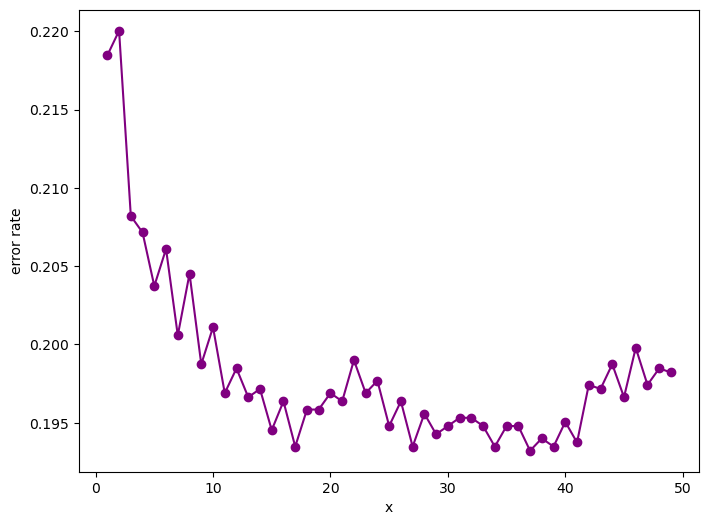

In [374]:
plt.figure(figsize = (8,6))
plt.plot(K_values,error_rate, color= "purple", linestyle= "-",marker="o")
plt.xlabel("x")
plt.ylabel("error rate")
plt.show()

In [423]:
Knn= KNeighborsClassifier(n_neighbors=38)
Knn.fit(x_train_scaled, y_train)
pred_1= Knn.predict(X_test)

In [376]:
confusion_matrix(y_test,pred_1)

array([[   0, 2436],
       [   0, 1368]], dtype=int64)

In [425]:
z=classification_report(y_test,pred_1)

C:\Users\HP\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\HP\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\HP\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [427]:
print(z)

              precision    recall  f1-score   support

           0       0.00      0.00      0.00      2436
           1       0.36      1.00      0.53      1368

    accuracy                           0.36      3804
   macro avg       0.18      0.50      0.26      3804
weighted avg       0.13      0.36      0.19      3804



In [379]:
knn = KNeighborsClassifier(n_neighbors=38)
knn.fit(x_train_scaled, y_train)
y_pred_knn = knn.predict(X_test_scaled)
accuracy_knn = accuracy_score(y_test, y_pred_knn)


In [380]:
confusion_matrix(y_test,y_pred_knn)

array([[2349,   87],
       [ 585,  783]], dtype=int64)

In [381]:


zp=classification_report(y_test,y_pred_knn)

In [382]:
print(zp)

              precision    recall  f1-score   support

           0       0.80      0.96      0.87      2436
           1       0.90      0.57      0.70      1368

    accuracy                           0.82      3804
   macro avg       0.85      0.77      0.79      3804
weighted avg       0.84      0.82      0.81      3804



In [383]:
print(accuracy_knn)

0.8233438485804416


In [384]:
model = LogisticRegression()
model.fit(X_train,y_train)
y_predited = model.predict(X_test)

C:\Users\HP\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [386]:
x

array([[ 28.7967,  16.0021,   2.6449, ...,  -8.2027,  40.092 ,  81.8828],
       [ 31.6036,  11.7235,   2.5185, ...,  -9.9574,   6.3609, 205.261 ],
       [162.052 , 136.031 ,   4.0612, ..., -45.216 ,  76.96  , 256.788 ],
       ...,
       [ 75.4455,  47.5305,   3.4483, ...,  -9.4662,  30.2987, 256.5166],
       [120.5135,  76.9018,   3.9939, ..., -63.8389,  84.6874, 408.3166],
       [187.1814,  53.0014,   3.2093, ...,  31.4755,  52.731 , 272.3174]])

In [387]:
accuracy_score(y_test,y_predited)

0.7836487907465826

In [388]:
x

array([[ 28.7967,  16.0021,   2.6449, ...,  -8.2027,  40.092 ,  81.8828],
       [ 31.6036,  11.7235,   2.5185, ...,  -9.9574,   6.3609, 205.261 ],
       [162.052 , 136.031 ,   4.0612, ..., -45.216 ,  76.96  , 256.788 ],
       ...,
       [ 75.4455,  47.5305,   3.4483, ...,  -9.4662,  30.2987, 256.5166],
       [120.5135,  76.9018,   3.9939, ..., -63.8389,  84.6874, 408.3166],
       [187.1814,  53.0014,   3.2093, ...,  31.4755,  52.731 , 272.3174]])

In [417]:
def add(a,b,c,d,e):
    return a+b+c+d+e

result = add(5,3,34,89,3)
print(result)

134
